In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns
import random
from pathlib import Path
import datetime
import joblib
import shutil
from scipy.ndimage import gaussian_filter
from scipy.signal import find_peaks
from statistics import mean
# from sklearn.metrics.pairwise import cosine_similarity

sys.path.insert(0, "../../Python/cellular_cycle")
from model_fxns import get_traj, plot_traj, restructProt, cosine_similarity, get_cos_similarities


# locations of previously generated simulation data
SAVE_DIR = Path('~/ECM_mod_output').expanduser()
SAVE_DIR.mkdir(exist_ok=True)   # create the directory if it doesn't exist  

SAVEFILES = True
OVERWRITE = False

EMBED_DIR = Path('../../Data','UMAP_embedding_ode') # location of saved embedding files for each condition

SET_JPARAM = False # Set the parameters for the simulation

sys_type = sys.platform

output_from = 1 # 1: original, 3: 03_ECM_model_output.ipynb, 4: 04_Stoch_sims_for_UMAP.ipynb

if sys_type == 'darwin':
    sys_name = 'mac'
elif sys_type == 'win32': 
    sys_name = 'win'
elif sys_type == 'linux': 
    sys_name = 'linux'

In [2]:
rcParams.update({'figure.autolayout': True})

### Load UMAP embeddings

`all_embedding_ode_conds_mac_from_04.sav` should have:
```
ODE_sim_DMSO_stiff_000_orig.csv
ODE_sim_DMSO_stiff_029_orig.csv
ODE_sim_DMSO_stiff_049_orig.csv
ODE_sim_DMSO_stiff_074_orig.csv
ODE_sim_DMSO_stiff_099_orig.csv
ODE_sim_ERL_stiff_000_orig.csv
ODE_sim_ERL_stiff_029_orig.csv
ODE_sim_ERL_stiff_049_orig.csv
ODE_sim_ERL_stiff_074_orig.csv
ODE_sim_ERL_stiff_099_orig.csv
```

`all_embedding_ode_conds_mac_from_03.sav` should be in the following order:
```
0, stiff_DMSO
1, stiff_ERL
2, int_DMSO
3, int_ERL
4, soft_DMSO
5, soft_ERL
```



In [3]:
if output_from == 1:
    embed_source = 'orig'
else:
    embed_source = f'from_0{output_from}'

all_embed_odes = joblib.load(Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_{embed_source}.sav'))
all_embed_odes.shape

(20000, 2)

In [4]:
all_embed_stoch = joblib.load(Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_{embed_source}.sav')) # output of 05_UMAP_of_stoch_sims.ipynb (experimental conds)
all_embed_stoch.shape

(399910, 2)

### Define conditions and associated annotations
condition names, colors, line types, etc.

In [5]:
conds = ['0.0 DMSO', '0.3 DMSO', '0.5 DMSO', '0.75 DMSO', '1.0 DMSO','0.0 ERL', '0.3 ERL', '0.5 ERL', '0.75 ERL', '1.0 ERL',]
colors_blue = plt.cm.Blues(np.linspace(0,1,7))
colors_red = plt.cm.Reds(np.linspace(0,1,6))
cond_colors = [colors_blue[2], colors_blue[3], colors_blue[4], colors_blue[5], colors_blue[6], colors_red[1], colors_red[2], colors_red[3], colors_red[4], colors_red[5],]
conds_idx = [0,1,2,3,4,5,6,7,8,9,]
plot_ode_len = [120,100,0,100,60,150,0,80,0,60,]
line_type = ['-', '-', '-', '-', '-', '--', '--', '--', '--', '--',]

# conds_idx_exp = [0,2,4,5,7,9,]
# exp_conds = [conds[i] for i in conds_idx_exp]
# exp_conds_names = ['soft DMSO', 'int DMSO', 'stiff DMSO', 'soft ERL', 'int ERL', 'stiff ERL',]

# lyap_conds_idx = [0,1,3,4,5,7,9,]
# lyap_conds = [conds[i] for i in lyap_conds_idx]

# colors_accent = plt.cm.jet(np.linspace(0,1,10))

### Load simulation data

In [6]:
all_prot = joblib.load(Path(SAVE_DIR, f'all_prot_stoch_conds_{sys_name}_{embed_source}.sav'))
all_prot.shape

(399910, 900)

In [7]:
trk_len = 2000 # length of ODE trajectories
 
if output_from == 3:
    num_conds = 6 # experimental conditions
elif output_from == 1 or output_from == 4:
    num_conds = 10
trk_len_stoch = int(len(all_embed_stoch)/num_conds) # lyapunov-determined stiffness conditions

embed_array = all_embed_odes
embed_array_stoch = all_embed_stoch

<Axes: title={'center': '0.0 ERL'}>

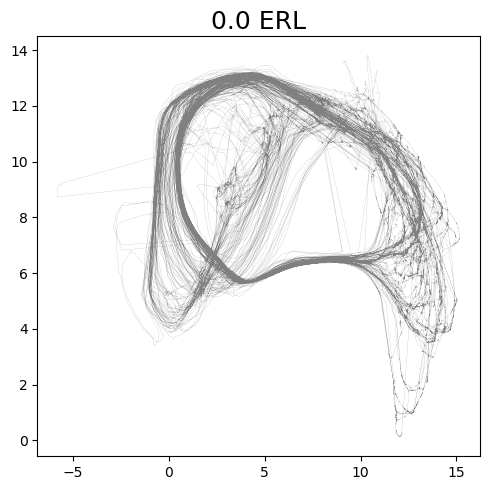

In [8]:
plot_traj(embed_array_stoch, 5, trk_len_stoch, title=conds[5])

### Plot experimental conditions

In [9]:
# plot parameters
size = (5,5)
l = trk_len
lw=2

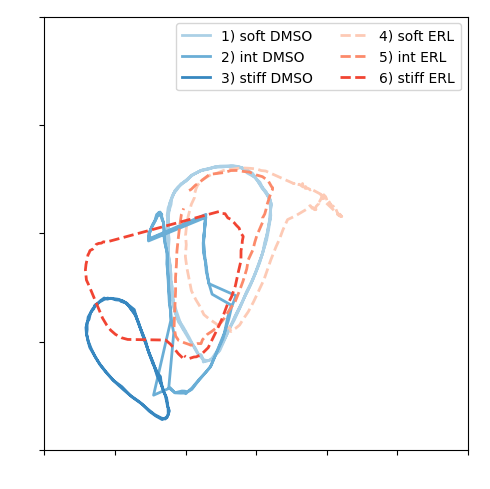

In [10]:
fig = plt.figure(figsize=size)

plt.plot(embed_array[0*l:0*l+150,0], 
         embed_array[0*l:0*l+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='1) soft DMSO')
plt.plot(embed_array[5*l:5*l+150,0], 
         embed_array[5*l:5*l+150,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[1], label='4) soft ERL')
plt.plot(embed_array[2*l:2*l+100,0], 
         embed_array[2*l:2*l+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='2) int DMSO')
plt.plot(embed_array[7*l:7*l+60,0], 
         embed_array[7*l:7*l+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[2], label='5) int ERL')
plt.plot(embed_array[4*l:4*l+100,0], 
         embed_array[4*l:4*l+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[4], label='3) stiff DMSO')
plt.plot(embed_array[9*l:9*l+55,0], 
         embed_array[9*l:9*l+55,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6) stiff ERL')




plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [0,2,4,1,3,5]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)

### Plot figure


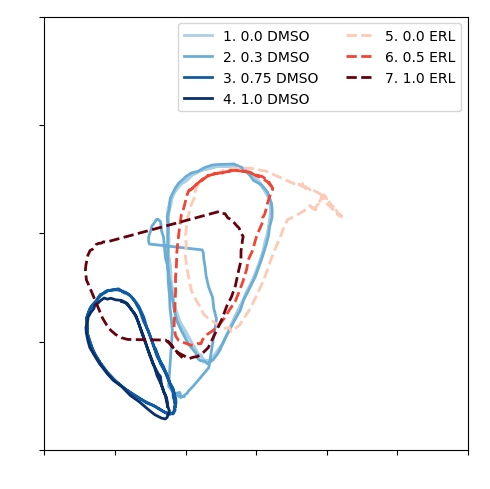

In [11]:
fig = plt.figure(figsize=size)

for i,x in enumerate([0,1,3,4,5,7,9,]):
    plt.plot(embed_array[x*l:x*l+plot_ode_len[x],0], 
             embed_array[x*l:x*l+plot_ode_len[x],1], 
             ls=line_type[x], lw=lw, alpha=1, color=cond_colors[x], label=f'{i+1}. {conds[x]}')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [0,1,2,3,4,5,6,]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)

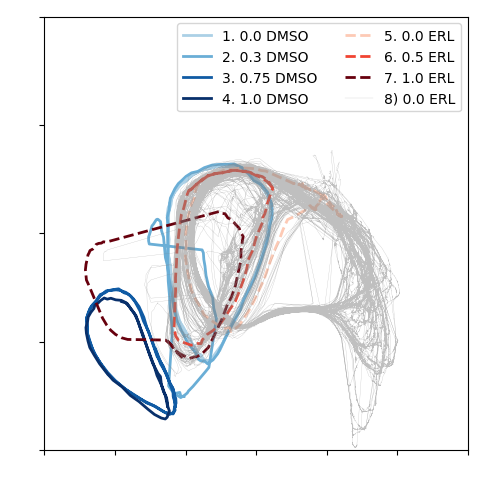

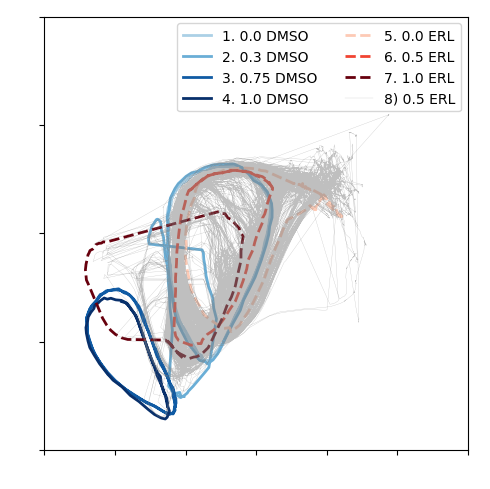

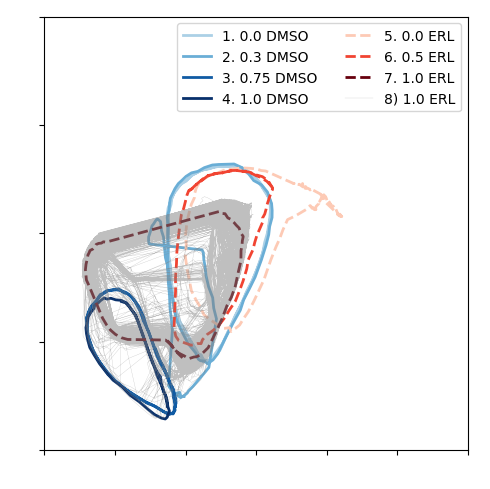

In [12]:
for cond_i,cond_x in enumerate([5,7,9,]):
    lw = 2
    fig = plt.figure(figsize=size)


    for i,x in enumerate([0,1,3,4,5,7,9,]):
        plt.plot(embed_array[x*l:x*l+plot_ode_len[x],0], 
                embed_array[x*l:x*l+plot_ode_len[x],1], 
                ls=line_type[x], lw=lw, alpha=1, color=cond_colors[x], label=f'{i+1}. {conds[x]}')

    plt.plot(embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch,0], 
            embed_array_stoch[cond_x*trk_len_stoch:(cond_x+1)*trk_len_stoch,1], 
            lw=0.2, alpha=0.5, color='gray', label=f'8) {conds[cond_x]}')


    plt.xlim(-5,20)
    plt.ylim(0, 15)
    plt.xticks(np.arange(-10, 21, step=5))
    plt.yticks(np.arange(0, 21, step=5))

    plt.xticks(color='w')
    plt.yticks(color='w')

    handles, labels = plt.gca().get_legend_handles_labels()
    order = [0,1,2,3,4,5,6,7,]
    leg = plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)

    filepath = Path(SAVE_DIR,f'{conds[cond_x]}_stoch.png')
    if SAVEFILES and (not filepath.exists() or OVERWRITE):
        plt.savefig(filepath, format='png', dpi=300)


In [13]:
all_time_tmp = joblib.load(Path(SAVE_DIR, f'all_time_tmp_{sys_name}_{embed_source}.sav'))


In [14]:
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']

# order = [0,1,3,4,5,7,9,]

dmso_000_prot_df = pd.DataFrame(all_prot[0*trk_len_stoch:1*trk_len_stoch,:])
dmso_000_time_df = pd.DataFrame(all_time_tmp[0*trk_len_stoch:1*trk_len_stoch,:])
dmso_000_emb_df = pd.DataFrame(all_embed_stoch[0*trk_len_stoch:1*trk_len_stoch,:])

dmso_030_prot_df = pd.DataFrame(all_prot[1*trk_len_stoch:2*trk_len_stoch,:])
dmso_030_time_df = pd.DataFrame(all_time_tmp[1*trk_len_stoch:2*trk_len_stoch,:])
dmso_030_emb_df = pd.DataFrame(all_embed_stoch[1*trk_len_stoch:2*trk_len_stoch,:])

dmso_050_prot_df = pd.DataFrame(all_prot[2*trk_len_stoch:3*trk_len_stoch,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[2*trk_len_stoch:3*trk_len_stoch,:])
dmso_050_emb_df = pd.DataFrame(all_embed_stoch[2*trk_len_stoch:3*trk_len_stoch,:])

dmso_070_prot_df = pd.DataFrame(all_prot[3*trk_len_stoch:4*trk_len_stoch,:])
dmso_070_time_df = pd.DataFrame(all_time_tmp[3*trk_len_stoch:4*trk_len_stoch,:])
dmso_070_emb_df = pd.DataFrame(all_embed_stoch[3*trk_len_stoch:4*trk_len_stoch,:])

dmso_099_prot_df = pd.DataFrame(all_prot[4*trk_len_stoch:5*trk_len_stoch,:])
dmso_099_time_df = pd.DataFrame(all_time_tmp[4*trk_len_stoch:5*trk_len_stoch,:])
dmso_099_emb_df = pd.DataFrame(all_embed_stoch[4*trk_len_stoch:5*trk_len_stoch,:])

erl_000_prot_df = pd.DataFrame(all_prot[5*trk_len_stoch:6*trk_len_stoch,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[5*trk_len_stoch:6*trk_len_stoch,:])
erl_000_emb_df = pd.DataFrame(all_embed_stoch[5*trk_len_stoch:6*trk_len_stoch,:])

erl_050_prot_df = pd.DataFrame(all_prot[7*trk_len_stoch:8*trk_len_stoch,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[7*trk_len_stoch:8*trk_len_stoch,:])
erl_050_emb_df = pd.DataFrame(all_embed_stoch[7*trk_len_stoch:8*trk_len_stoch,:])

erl_099_prot_df = pd.DataFrame(all_prot[9*trk_len_stoch:10*trk_len_stoch,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[9*trk_len_stoch:10*trk_len_stoch,:])
erl_099_emb_df = pd.DataFrame(all_embed_stoch[9*trk_len_stoch:10*trk_len_stoch,:])


In [15]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)

In [16]:
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

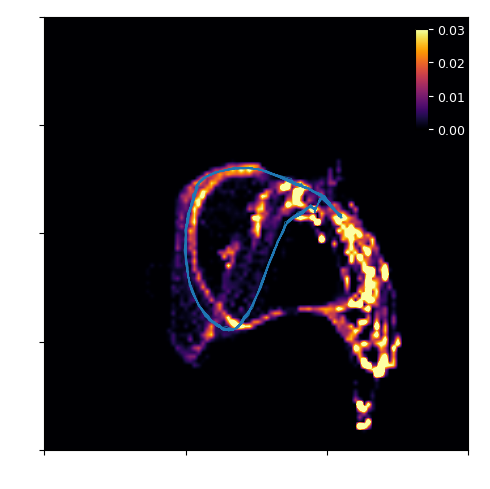

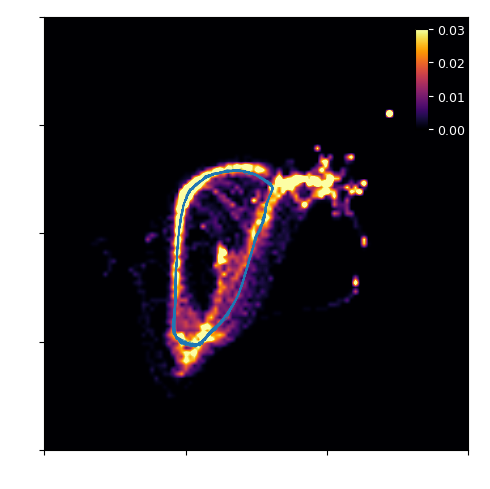

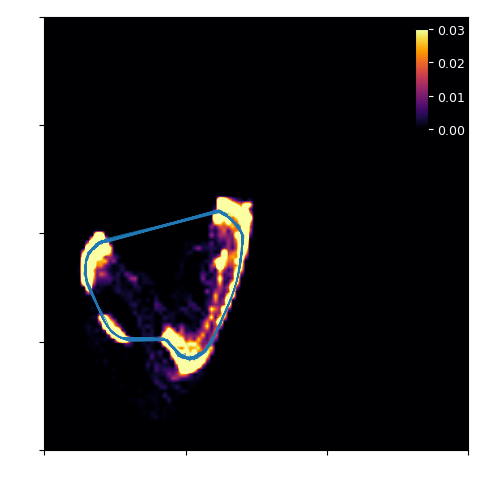

In [17]:
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

for cond_i,cond_x in enumerate([5,7,9,]):
    val = ['000','050','099'][cond_i]
    dat_name = f'umap_win_erl_{val}'
    dat = globals()[dat_name]

    fig = plt.figure(figsize=size)
    xmin, xmax = -10, 20
    ymin, ymax = 0, 20

    x = np.array(dat[0])
    y = np.array(dat[1])
    H, xedges, yedges = np.histogram2d(x, y, bins=100, range= [[xmin,xmax], [ymin,ymax]], density=True)
    # Apply gaussian filter
    sigma = [3, 3]
    H2 = gaussian_filter(H, sigma, mode='constant')

    ax = fig.gca()

    tmp = all_embed_odes[cond_x*trk_len:(cond_x+1)*trk_len,:]
    im = plt.imshow((np.rot90(H)), extent=[xmin, xmax, ymin, ymax], 
                    interpolation='bilinear', cmap='inferno', aspect='auto')
    im.set_clim(0, 0.03)
    plt.plot(tmp[200:,0], tmp[200:,1],
            lw=0.5, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)
    plt.xticks(np.arange(-10, 21, step=10))
    plt.yticks(np.arange(0, 21, step=5))


    plt.xticks(color='w')
    plt.yticks(color='w')

    cbar_ax = fig.add_axes([0.84, 0.73, 0.025, 0.2])
    cb = fig.colorbar(im, cax=cbar_ax)
    cb.ax.tick_params(labelsize=9)
    cb.ax.yaxis.set_tick_params(color='white')
    plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

    filepath = Path(SAVE_DIR,f'{dat_name}_heatmap.png')
    if SAVEFILES and (not filepath.exists() or OVERWRITE):
        plt.savefig(filepath, format='png', dpi=300)

### Define a function to calculate cosine similarity

### Calculate cosine similarity for adjacent vectors along a trajectory
For each trajectory, define the set of vectors each of size `v_len` and index offset of `offset` for their comparator vectors to calculate cosine similarity.


In [18]:
offset=1
v_len=1

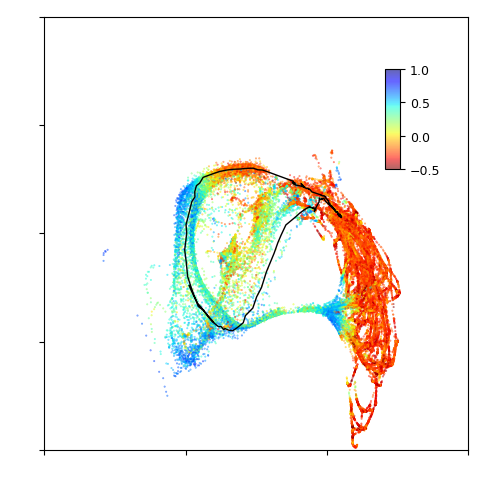

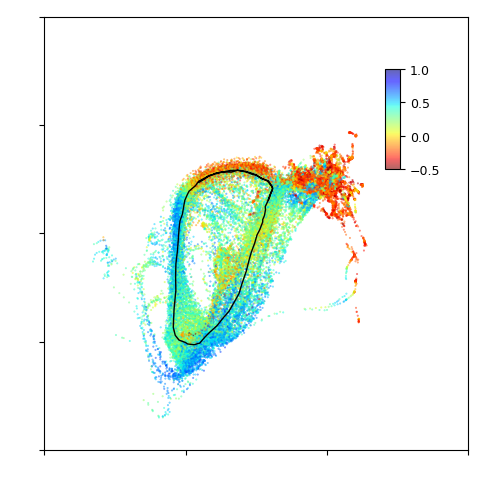

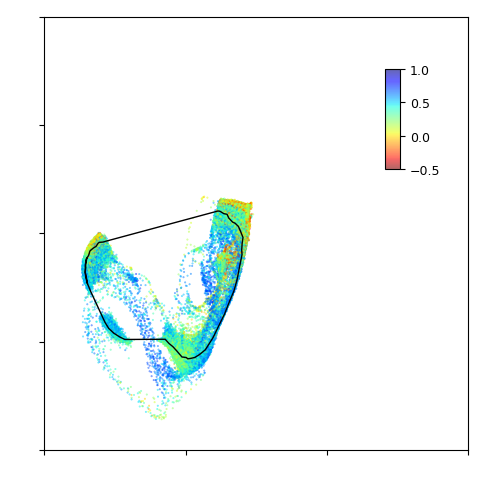

In [19]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

for cond_i,cond_x in enumerate([5,7,9,]):
    cos_vals = get_cos_similarities(get_traj(all_prot, cond_x, trk_len_stoch), v_len, offset)
    fig = plt.figure(figsize=size)
    dat = get_traj(embed_array_stoch, cond_x, trk_len_stoch-2)
    scatter1 = plt.scatter(dat[:,0], dat[:,1], s=0.2, alpha=0.6, vmin=-0.5, vmax=1, c=cos_vals, cmap='jet_r')

    tmp = get_traj(embed_array, cond_x, trk_len)
    plt.plot(tmp[500:(500+plot_ode_len[cond_x]),0], tmp[500:(500+plot_ode_len[cond_x]),1],
            lw=1, alpha=1, color='black')

    plt.xlim(-10,20)
    plt.ylim(0, 20)
    plt.xticks(np.arange(-10, 21, step=10))
    plt.yticks(np.arange(0, 21, step=5))

    plt.xticks(color='w')
    plt.yticks(color='w')

    cbar_ax = fig.add_axes([0.78, 0.65, 0.03, 0.2])
    cb = fig.colorbar(scatter1, cax=cbar_ax)
    cb.ax.tick_params(labelsize=9)

    filepath = Path(SAVE_DIR,f'{conds[cond_x]}_directionality.png')
    if SAVEFILES and (not filepath.exists() or OVERWRITE):
        plt.savefig(filepath, format='png', dpi=300)

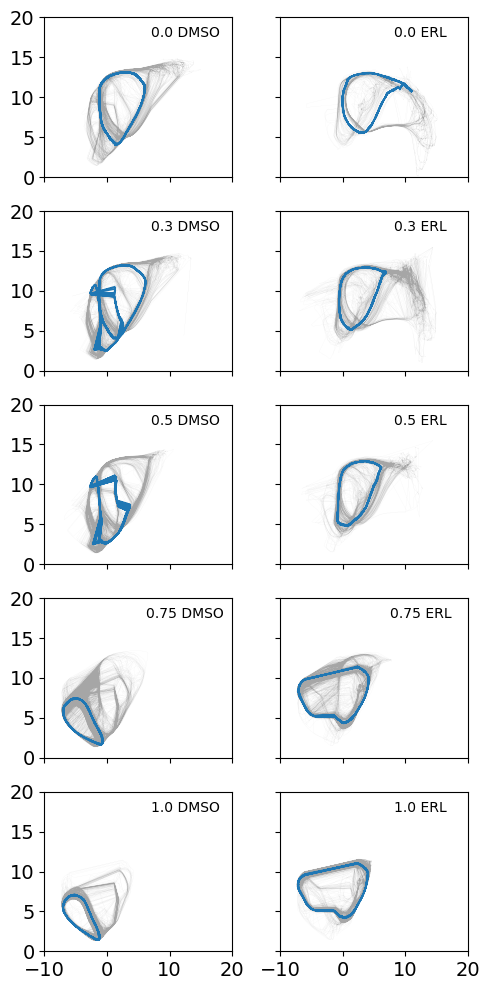

In [20]:
fig = plt.figure(figsize=(5,10))
p = 1
for n in [0,5,1,6,2,7,3,8,4,9]:
    plt.subplot(5,2,p)
    plt.plot(embed_array_stoch[n*trk_len_stoch:(n+1)*trk_len_stoch,0], 
             embed_array_stoch[n*trk_len_stoch:(n+1)*trk_len_stoch,1], lw=0.02, alpha=0.7, c='gray')
    plt.plot(embed_array[n*trk_len:(n+1)*trk_len,0], 
             embed_array[n*trk_len:(n+1)*trk_len,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
    plt.text(0.75, 0.9, f'{conds[n]}', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)
    if (p % 2) == 0:
        ax.yaxis.set_tick_params(labelleft=False)
    if p<9:
        ax.xaxis.set_tick_params(labelleft=False)
    p += 1